# Imports

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np 
import scipy.stats as stats #(not in environment yet?)
import sys
from statsmodels.stats.multicomp import pairwise_tukeyhsd #(not in envirnoment yet)
import seaborn as sns
import pingouin as pg

# from statannotations.Annotator import Annotator

# Loading Data

In [2]:
df = pd.read_csv('../data/csv_files/df.csv')

columns = df.columns
column_names = df.columns.tolist()

# Descriptive Statistics after Exclusion

In [3]:
# Number of participants after exclusion
good_partis = df['subID'].unique()
len_good_partis = len(good_partis)
print(f'There were {len_good_partis} participants in the dataset that went into the final analysis.')

# Gender
# Group the DataFrame by sub_ID and get the first occurrence of sub_gender in each group
gender_by_sub_id = df.groupby('subID')['sub_gender'].first()

# Count the instances of 'M' within the grouped sub_gender data
gender_counts = gender_by_sub_id.value_counts()
if 'M' in gender_counts:
    count_of_males = gender_counts['M']
    print(f"Count of male Participants: {count_of_males}")

# Calculate the proportion
gender_propo = count_of_males / len(good_partis)
print('Proportion of male participants:', gender_propo)

# age
age_by_sub_id = df.groupby('subID')['sub_age'].first()
mean_age = age_by_sub_id.mean()
sd_age = age_by_sub_id.std()
print(f'The mean age of participants was {mean_age:.2f} with the standard deviation of {sd_age:.2f}')

# number of participants with and without mask
masked_pp = df.groupby('subID')['mask'].first()
mask_counts = masked_pp.value_counts()
print(f"There were {mask_counts[1]} Participants that had the Version of the task including the mask and {mask_counts[0]} without the mask.")

# number of participants per stimuli set
stimset_pp = df.groupby('subID')['stimuli_set'].first()
stimset_counts = stimset_pp.value_counts()
print(f"There were {stimset_counts['stimuli_set1']} Participants tested with stimuli set 1, {stimset_counts['stimuli_set2']} with stimuli set 2, and {stimset_counts['stimuli_set3']} with stimuli set 3.")

There were 42 participants in the dataset that went into the final analysis.
Count of male Participants: 12
Proportion of male participants: 0.2857142857142857
The mean age of participants was 25.31 with the standard deviation of 4.40
There were 20 Participants that had the Version of the task including the mask and 22 without the mask.
There were 15 Participants tested with stimuli set 1, 14 with stimuli set 2, and 13 with stimuli set 3.


# Confidence / Manipulation / Accuracy Checks

## Mask vs. No Mask 

In [4]:
# Mask vs no Mask
mask_data = []
no_mask_data = []
for i in good_partis:
    participant_data = df[df['subID'] == i]
    if (participant_data['mask']==1).all():
        mask_data.append(participant_data['acc_trial_concrete_cued'].mean())
    else:
        no_mask_data.append(participant_data['acc_trial_concrete_cued'].mean())
# mask_data = df.loc[df['mask'] == 1, 'acc_trial_concrete_cued']
# nomask_data = df.loc[df['mask'] == 0, 'acc_trial_concrete_cued']

result_df = pg.ttest(mask_data, no_mask_data)
display(result_df)

# Access specific properties
p_value = result_df['p-val'].values
t_statistic = result_df['T'].values

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between the mask version and the no-mask version.")
else:
    print("The t-test does not indicate a significant difference in accuracy between the mask version and the no-mask version.")


,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,0.54768,38.845537,two-sided,0.587045,"[-0.03, 0.05]",0.16702,0.342,0.082466


The t-test does not indicate a significant difference in accuracy between the mask version and the no-mask version.


## Upside down vs upright accuracy

In [5]:
# Note: doublecheck wether the specified degrees are consistent with the actual upright position of object during the experiment
# Note: are these the correct specifications for the degrees now? (90 - 270 & 270 - 90) - mind the vertical OR line
# Note: the length of the data of upright shown items is different from the length of the data of upside down shown items, they add up to the total though. Why?

results = []

# Iterate through each participant in good_partis
for i in good_partis:

    # Group the data for the current participant
    participant_data = df[df['subID'] == i]

    # Define filters for upright and upside-down orientations
    upright_filter = (participant_data['object_cued_rot'] < 90) | (participant_data['object_cued_rot'] > 270)
    upside_down_filter = (participant_data['object_cued_rot'] < 270) & (participant_data['object_cued_rot'] > 90)

    # Apply filters to the participant's data
    upright_data = participant_data[upright_filter]
    upside_down_data = participant_data[upside_down_filter]

    # Calculate the mean for upright and upside-down orientations
    mean_upright = upright_data['acc_trial_concrete_cued'].mean()
    mean_upside_down = upside_down_data['acc_trial_concrete_cued'].mean()

    # Store the results for the current participant
    results.append({'subID': i, 'mean_upright': mean_upright, 'mean_upside_down': mean_upside_down})

# Convert the results list to a DataFrame
upright_df = pd.DataFrame(results)

# nearly the same mean as in the codeblock above
mean_upright2 = upright_df['mean_upright'].mean()
mean_upsidedown2 = upright_df['mean_upside_down'].mean()
display(mean_upright2)
display(mean_upsidedown2)
# display(upright_df)

## Perform paired t-test using pingouin
ttest_result = pg.ttest(upright_df['mean_upright'], upright_df['mean_upside_down'])

# Print the t-test result
display(ttest_result)

# Access specific properties
p_value = ttest_result['p-val'].values
t_statistic = ttest_result['T'].values

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")


0.7262394235450277

0.7069065709918186

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,1.216029,82,two-sided,0.227463,"[-0.01, 0.05]",0.265359,0.433,0.224965


The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.


## Stimuli Sets

,Source,ddof1,ddof2,F,p-unc,np2
0,stimuli_set,2,39,1.566652,0.221596,0.074366


/tmp/ipykernel_2969730/3756199126.py:21: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(x='stimuli_set', y='acc_trial_concrete_cued', data=grouped_data_stim_sets, errorbar='se', linestyles="none", markers='_', scale=2) # Note: estimator='mean', -> doesnt seem to change anything


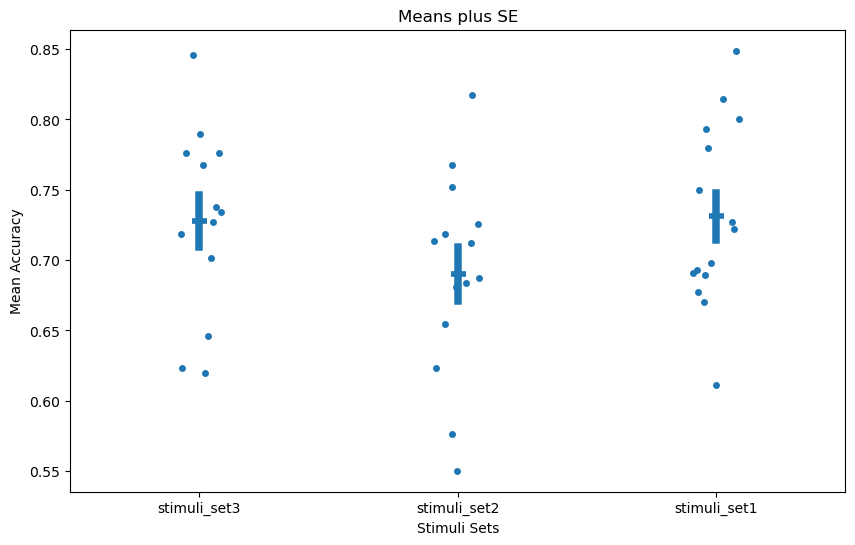

In [6]:
# Note: not done yet, stripplot not showing mean lines as expected 
# Note to self: I am using groupby differently here, grouping directly by subID which means I do not need a loop. Can I use it the same way in other situations? In this instance I group by subID and stimset when there is actually only one stimset per
# participant anyway. 

# Create an empty list to store grouped data for each participant
grouped_data_stim_sets = df.groupby(['subID', 'stimuli_set'])['acc_trial_concrete_cued'].mean().reset_index()

# ANOVA on grouped data by participant
anova_result_acc_stimset2 = pg.anova(data=grouped_data_stim_sets, dv='acc_trial_concrete_cued', between='stimuli_set')
display(anova_result_acc_stimset2)

# Plot boxplots for each participant
plt.figure(figsize=(10, 6))

# FutureWarning is related to the stripplot
sns.stripplot(x='stimuli_set', y='acc_trial_concrete_cued', data=grouped_data_stim_sets)
# Note: is se the right choice for the errorbar?
# "In short, when you mention ‘mean’, .aggregate() searches for a function mean belonging to pd.Series, i.e. pd.Series.mean().
# Whereas, if you mention mean (without quotes), .aggregate() will search for a function named mean in default Python, which is unavailable and will throw a NameError exception."
# What is the dot in the plot? Is that also some statistic already?
sns.pointplot(x='stimuli_set', y='acc_trial_concrete_cued', data=grouped_data_stim_sets, errorbar='se', linestyles="none", markers='_', scale=2) # Note: estimator='mean', -> doesnt seem to change anything
plt.title('Means plus SE')
plt.xlabel('Stimuli Sets')
plt.ylabel('Mean Accuracy')
plt.show()

## Mean accuracy by condition, oneway ANOVA

In [7]:
# Note: should I maybe do this on individual participants rather than the whole df? (do it in within a loop)

# does all three conditions in one and groups them by 'items_presented' which is the condition (can add .values at the end if I want only the answer values)
mean_acc = df['acc_trial_concrete_cued'].mean()
print("Mean accuracy for all conditions:", mean_acc)

mean_cond = df.groupby('items_presented')['acc_trial_concrete_cued'].mean()
print("Mean accuracy per condition:", mean_cond)

condition_means = mean_cond.tolist()
# why do I have the following line?
condition_labels = ['1', '2', '3']
# these turn out to be exactly the same size, I am a little suspicious that I indeed have exactly the same number of accuracy lines for every condition
# can remove this later, but might be interesting to check the number of samples per condition after I decide which participants to exclude
# len_sample_con1 = len(df[df['items_presented'] == 1])
# print('samples con1:', len_sample_con1)
# len_sample_con2 = len(df[df['items_presented'] == 2])
# print('samples con1:', len_sample_con2)
# len_sample_con3 = len(df[df['items_presented'] == 3])
# print('samples con1:', len_sample_con3)

# Pingouin ANOVA
# Note: should this also run on participants or the full data?
anova_result_acc_items = pg.anova(data=df, dv='acc_trial_concrete_cued', between='items_presented')
display('Anova Results', anova_result_acc_items.round(4))

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if anova_result_acc_items['p-unc'].values[0] < alpha:
    print("The one-way ANOVA indicates a significant difference in accuracy among the three conditions.\n")
    tukey = pg.pairwise_tukey(dv='acc_trial_concrete_cued', between='items_presented', data=df)
    display(tukey.round(4))
    significant_pairs = tukey[tukey['p-tukey'] < 0.05]
    for index, row in significant_pairs.iterrows():
        print(f"There is a significant difference between groups {row['A']} and {row['B']}.")
        print(f"Mean difference: {row['mean(A)'] - row['mean(B)']}")
else:
    print("The one-way ANOVA does not indicate a significant difference in accuracy among the three conditions.")


# plt.figure(figsize=(10,6))
# sns.barplot(data=df, y='acc_trial_concrete_cued', x='items_presented')
# plt.show()

Mean accuracy for all conditions: 0.7164765211640212
Mean accuracy per condition: items_presented
1    0.798363
2    0.694568
3    0.656498
Name: acc_trial_concrete_cued, dtype: float64


'Anova Results'

,Source,ddof1,ddof2,F,p-unc,np2
0,items_presented,2,24189,207.1247,0.0,0.0168


The one-way ANOVA indicates a significant difference in accuracy among the three conditions.



,A,B,mean(A),mean(B),diff,se,T,p-tukey,hedges
0,1,2,0.7984,0.6946,0.1038,0.0072,14.3855,0.0,0.2331
1,1,3,0.7984,0.6565,0.1419,0.0072,19.6619,0.0,0.3139
2,2,3,0.6946,0.6565,0.0381,0.0072,5.2764,0.0,0.0799


There is a significant difference between groups 1.0 and 2.0.
Mean difference: 0.1037946428571429
There is a significant difference between groups 1.0 and 3.0.
Mean difference: 0.1418650793650793
There is a significant difference between groups 2.0 and 3.0.
Mean difference: 0.0380704365079364


0.716476521164021

items_presented
1    0.798363
2    0.694568
3    0.656498
Name: acc_trial_concrete_cued, dtype: float64

,items_presented,subID,acc_trial_concrete_cued
0,1,Z16JQR,0.838542
1,2,Z16JQR,0.796875
2,3,Z16JQR,0.744792
0,1,C9A31N,0.729167
1,2,C9A31N,0.677083
...,...,...,...
1,2,XG7QAG,0.692708
2,3,XG7QAG,0.635417
0,1,30K8XE,0.614583
1,2,30K8XE,0.552083


,Source,ddof1,ddof2,F,p-unc,np2
0,items_presented,2,123,38.8442,0.0,0.3871


The one-way ANOVA indicates a significant difference in accuracy among the three conditions.



,A,B,mean(A),mean(B),diff,se,T,p-tukey,hedges
0,1,2,0.7984,0.6946,0.1038,0.0072,14.3855,0.0,0.2331
1,1,3,0.7984,0.6565,0.1419,0.0072,19.6619,0.0,0.3139
2,2,3,0.6946,0.6565,0.0381,0.0072,5.2764,0.0,0.0799


There is a significant difference between groups 1.0 and 2.0.
Mean difference: 0.1037946428571429
There is a significant difference between groups 1.0 and 3.0.
Mean difference: 0.1418650793650793
There is a significant difference between groups 2.0 and 3.0.
Mean difference: 0.0380704365079364


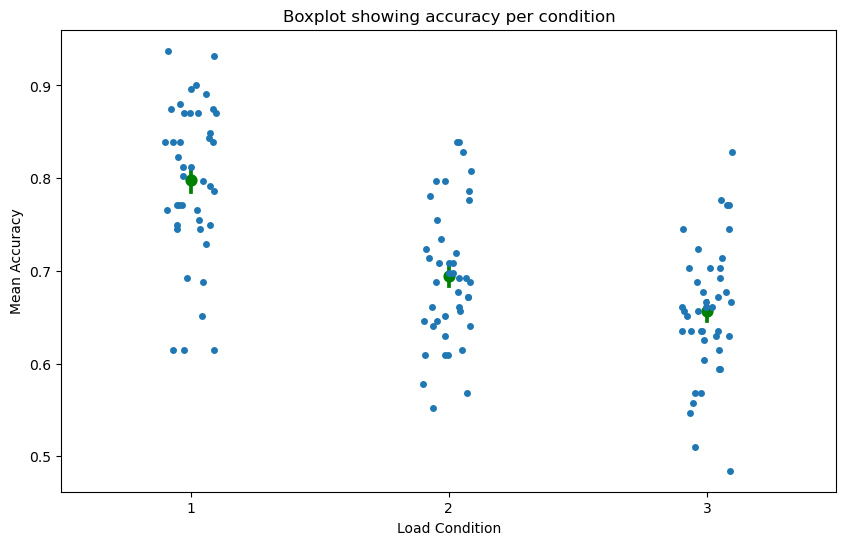

In [8]:
# mean for all conditions
mean_acc = df.groupby('subID')['acc_trial_concrete_cued'].mean().mean()
display(mean_acc)

# mean per condition exactly the same as in previous version without collapsing by participant first. does that make sense?
mean_per_con = df.groupby('items_presented')['acc_trial_concrete_cued'].mean()
display(mean_per_con)

results = []
for i in good_partis:
    participant_data_acc = df.loc[df['subID'] == i].groupby(['items_presented', 'subID'])['acc_trial_concrete_cued'].mean().reset_index()
    #participant_data_acc = df[df['subID'] == i].groupby(['block_number', 'subID'])['acc_trial_concrete_cued'].mean().reset_index()
    # display(participant_data_acc)
    results.append(participant_data_acc)

results_acc_con = pd.concat(results)
display(results_acc_con)


 # Pingouin ANOVA
anova_result_acc_items = pg.anova(data=results_acc_con, dv='acc_trial_concrete_cued', between='items_presented')
display(anova_result_acc_items.round(4))

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if anova_result_acc_items['p-unc'].values[0] < alpha:
    print("The one-way ANOVA indicates a significant difference in accuracy among the three conditions.\n")
    tukey = pg.pairwise_tukey(dv='acc_trial_concrete_cued', between='items_presented', data=df)
    display(tukey.round(4))
    significant_pairs = tukey[tukey['p-tukey'] < 0.05]
    for index, row in significant_pairs.iterrows():
        print(f"There is a significant difference between groups {row['A']} and {row['B']}.")
        print(f"Mean difference: {row['mean(A)'] - row['mean(B)']}")
else:
    print("The one-way ANOVA does not indicate a significant difference in accuracy among the three conditions.")


# Plot boxplots for each participant
plt.figure(figsize=(10, 6))
sns.stripplot(x='items_presented', y='acc_trial_concrete_cued', data=results_acc_con)
sns.pointplot(x='items_presented', y='acc_trial_concrete_cued', data=results_acc_con, estimator='mean', errorbar='se',linestyles="none", color= "g")
plt.title('Boxplot showing accuracy per condition')
plt.xlabel('Load Condition')
plt.ylabel('Mean Accuracy')
plt.show()

## Accuraccy over time 

,subID,block_number,acc_trial_concrete_cued
0,1L974Q,1,0.666667
1,1L974Q,2,0.722222
2,1L974Q,3,0.722222
3,1L974Q,4,0.722222
4,1L974Q,5,0.861111
...,...,...,...
667,ZGV9KP,12,0.638889
668,ZGV9KP,13,0.666667
669,ZGV9KP,14,0.694444
670,ZGV9KP,15,0.777778


,block_number,acc_trial_concrete_cued
0,1,0.657407
1,2,0.668651
2,3,0.698413
3,4,0.695767
4,5,0.716270
5,6,0.703704
6,7,0.722222
7,8,0.750661
8,9,0.709656
9,10,0.744048


,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,0.6790,0.0087,78.1131,0.0,0.0347,0.0332,0.6619,0.6961
1,block_number,0.0044,0.0009,4.9044,0.0,0.0347,0.0332,0.0026,0.0062


,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,0.6790,0.0088,77.1265,0.0000,0.6262,0.5995,0.6601,0.6979
1,block_number,0.0044,0.0009,4.8424,0.0003,0.6262,0.5995,0.0025,0.0064


The R2 of the model is 0.034 and the adjusted R2 is 0.033, which means that our model roughly explains ~3% of the total variance in the accuracy over the blocks.


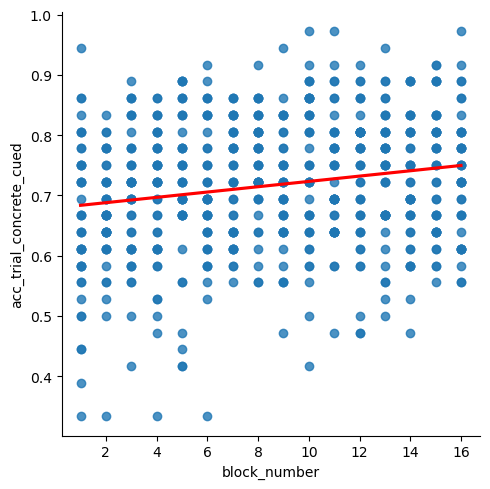

In [9]:
# Note: I could have also done this per trial 
# Note: do I need to use a residual plot first to check if I violate the assumptions of a linear regression?


mean_block_allp = df.groupby(['subID', 'block_number'])['acc_trial_concrete_cued'].mean().reset_index()
display(mean_block_allp)
mean_block_subid = mean_block_allp.groupby('block_number')['acc_trial_concrete_cued'].mean().reset_index()
display(mean_block_subid)

# Note: which one of the two following linear regressions is correct? Probably the first, there are 16 data point for every participant (one for each block)
# the second takes the mean data per block, so 16 data points in total
# linear regression
lm_results = pg.linear_regression(mean_block_allp['block_number'], mean_block_allp['acc_trial_concrete_cued'])
display(lm_results.round(4))

lm_results = pg.linear_regression(mean_block_subid['block_number'], mean_block_subid['acc_trial_concrete_cued'])
display(lm_results.round(4))


## WHAT IS THE DATA
# Note: could there be a better plot to use?

sns.lmplot(x='block_number', y='acc_trial_concrete_cued', data= mean_block_allp, ci=None, line_kws={'color': 'red'})

# print statement 
print('The R2 of the model is 0.034 and the adjusted R2 is 0.033, which means that our model roughly explains ~3% of the total variance in the accuracy over the blocks.') # Note: is this interpretation correct? Why is the amount of variance explained so low?

# check effect size

# Circular Stuff

## Oblique Effect

Cardinal_Category
Cardinal    0.735101
Oblique     0.698051
Name: acc_trial_concrete_cued, dtype: float64

42


,index,Cardinal_Category,acc_trial_concrete_cued
0,0,Cardinal,0.836066
1,1,Oblique,0.745387
2,0,Cardinal,0.725000
3,1,Oblique,0.638514
4,0,Cardinal,0.842657
...,...,...,...
79,1,Oblique,0.749164
80,0,Cardinal,0.697917
81,1,Oblique,0.729167
82,0,Cardinal,0.537906


84


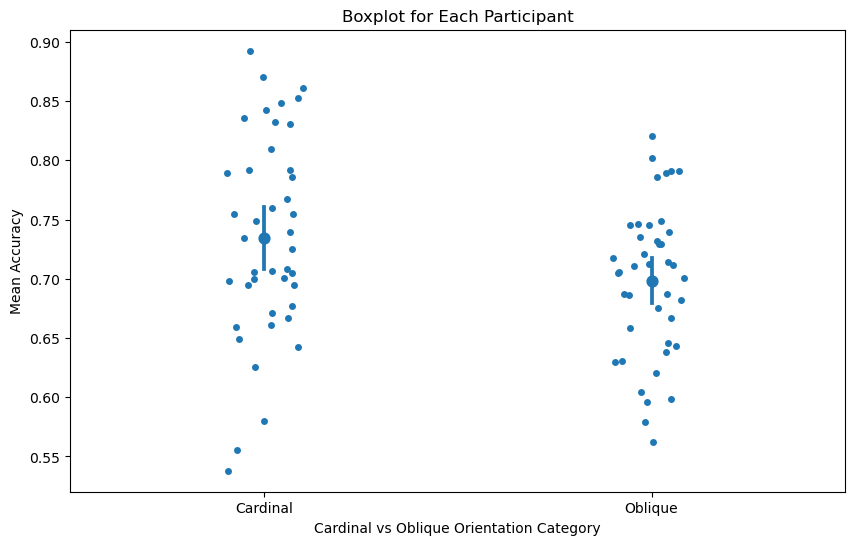

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,2.218838,82,two-sided,0.029261,"[0.0, 0.07]",0.48419,1.892,0.592072


The t-test indicates a significant difference between accuracy in oblique vs. cardinal orientations


In [10]:
# Note: here I have 84 data points, probably two for each participant, that seems correct, I took a mean for the accuracy of every participant in both the cardinal and the oblique positions 

# orientations closest to the cardinal axes
orientation_subset_cardinal = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]

# Create a new column to indicate the categories
df['Cardinal_Category'] = df['object_cued_rot'].apply(lambda x: 'Cardinal' if x in orientation_subset_cardinal else 'Oblique')

# Calculate mean accuracy for each category
mean_per_category = df.groupby('Cardinal_Category')['acc_trial_concrete_cued'].mean()
display(mean_per_category)

# Create an empty list to store grouped data for each participant
grouped_data_list = []

# Iterate through each participant in good_partis
for i in good_partis:
    # Group the data for the current participant
    data = df[df['subID'] == i].groupby(['Cardinal_Category'])['acc_trial_concrete_cued'].mean().reset_index()
    
    # Append the grouped data to the list
    grouped_data_list.append(data)
print(len(grouped_data_list))
# Concatenate the list of DataFrames into a single DataFrame
final_grouped_data_obli = pd.concat(grouped_data_list).reset_index()
display(final_grouped_data_obli)
print(len(final_grouped_data_obli))

# Plot boxplots for each participant
plt.figure(figsize=(10, 6))
sns.stripplot(x='Cardinal_Category', y='acc_trial_concrete_cued', data=final_grouped_data_obli)
sns.pointplot(x='Cardinal_Category', y='acc_trial_concrete_cued', data=final_grouped_data_obli, linestyles='none')
plt.title('Boxplot for Each Participant')
plt.xlabel('Cardinal vs Oblique Orientation Category')
plt.ylabel('Mean Accuracy')
plt.show()


oblique_data = final_grouped_data_obli[final_grouped_data_obli['Cardinal_Category'] == 'Oblique']['acc_trial_concrete_cued']
cardinal_data = final_grouped_data_obli[final_grouped_data_obli['Cardinal_Category'] == 'Cardinal']['acc_trial_concrete_cued']

# Statistics
# these have different results than the statistics below that I originally computed
# Note: which other statistic was I talking about here?

# t_statistic, p_value = stats.ttest_ind(cardinal_data, oblique_data)
result_ttest_obli = pg.ttest(cardinal_data, oblique_data)
display(result_ttest_obli)

# Access specific properties
p_value = result_ttest_obli['p-val'].values
t_statistic = result_ttest_obli['T'].values

# Define the significance level (alpha)
alpha = 0.05

if p_value < alpha:
    print("The t-test indicates a significant difference between accuracy in oblique vs. cardinal orientations")
else:
    print("The t-test does not indicate a significant difference between accuracy in oblique vs. cardinal orientations")





,Cardinal_Category,mean,std,subID,items_presented
0,Cardinal,0.895833,0.307080,Z16JQR,1
1,Oblique,0.781250,0.415569,Z16JQR,1
0,Cardinal,0.781250,0.415569,C9A31N,1
1,Oblique,0.677083,0.470046,C9A31N,1
0,Cardinal,0.895833,0.307080,LPULPG,1
...,...,...,...,...,...
1,Oblique,0.679245,0.468984,R62CC9,3
0,Cardinal,0.616162,0.488794,XG7QAG,3
1,Oblique,0.655914,0.477644,XG7QAG,3
0,Cardinal,0.505747,0.502865,30K8XE,3


/mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/lib/python3.10/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  data.groupby(level=1, axis=1, observed=True, group_keys=False)
/mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/lib/python3.10/site-packages/pingouin/distribution.py:507: FutureWarning: DataFrameGroupBy.diff with axis=1 is deprecated and will be removed in a future version. Operate on the un-grouped DataFrame instead
  data.groupby(level=1, axis=1, observed=True, group_keys=False)


,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,Cardinal_Category,0.0818,1,41,0.0818,13.8862,0.0006,0.0006,0.0420,1.0000
1,items_presented,0.9056,2,82,0.4528,142.0980,0.0000,0.0000,0.3270,0.8479
2,Cardinal_Category * items_presented,0.0077,2,82,0.0039,1.6561,0.1972,0.2018,0.0041,0.8403


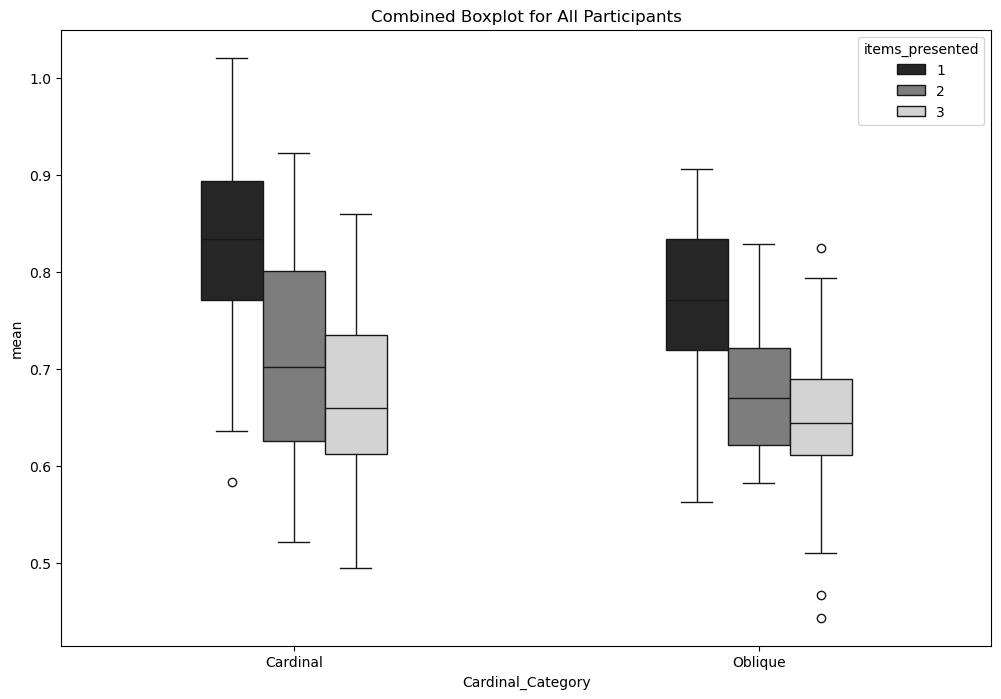

In [11]:
# comparing load conditions:

all_p_obli_con = pd.DataFrame()

all_p_obli_con1 = []
all_p_obli_con2 = []
all_p_obli_con3 = []

# Iterate through each participant in good_partis
for i in good_partis:
    # Group the data for the current participant
    # data = df[df['subID'] == i].groupby(['Cardinal_Category'])['acc_trial_concrete_cued'].mean()
    participant_data_obli_con = df.loc[df['subID'] == i, ['Cardinal_Category', 'acc_trial_concrete_cued', 'object_cued_rot', 'items_presented']]
    #participant_data1 = df.loc[(df['subID'] == i) & (df['items_presented'] == 1), 'acc_trial_concrete_cued']
        # condition 1
    #bp_con1 = participant_data.loc[participant_data['items_presented'] == 1].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_obli_con1 = participant_data_obli_con.loc[participant_data_obli_con['items_presented'] == 1].groupby('Cardinal_Category')['acc_trial_concrete_cued'].agg(['mean', 'std']).reset_index()
    acc_obli_con1['subID'] = i
    acc_obli_con1['items_presented'] = 1
    all_p_obli_con1.append(acc_obli_con1)

    # condition 2
    #bp_con2 = participant_data.loc[participant_data['items_presented'] == 2].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_obli_con2 = participant_data_obli_con.loc[participant_data_obli_con['items_presented'] == 2].groupby('Cardinal_Category')['acc_trial_concrete_cued'].agg(['mean', 'std']).reset_index()
    acc_obli_con2['subID'] = i
    acc_obli_con2['items_presented'] = 2
    all_p_obli_con2.append(acc_obli_con2)

    #bp_con3 = participant_data.loc[participant_data['items_presented'] == 3].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_obli_con3 = participant_data_obli_con.loc[participant_data_obli_con['items_presented'] == 3].groupby('Cardinal_Category')['acc_trial_concrete_cued'].agg(['mean', 'std']).reset_index()
    acc_obli_con3['subID'] = i
    acc_obli_con3['items_presented'] = 3
    all_p_obli_con3.append(acc_obli_con3)

all_p_obli_con1_df = pd.concat(all_p_obli_con1)
all_p_obli_con2_df = pd.concat(all_p_obli_con2)
all_p_obli_con3_df = pd.concat(all_p_obli_con3)

all_p_obli_con = pd.concat([all_p_obli_con1_df, all_p_obli_con2_df, all_p_obli_con3_df])
display(all_p_obli_con)
    
# Box plot for all conditions for all participants
plt.figure(figsize=(12, 8))

# Subplot for all conditions
# sharey=True
plt.subplot() #221
sns.boxplot(x='Cardinal_Category', y='mean', hue='items_presented', data=all_p_obli_con, width=0.4, palette='dark:lightgray')
plt.title('Combined Boxplot for All Participants')

# Anova

# should I do a repeated measures anova here?
# run it on the df or the all_p_obli_c

# Perform ANOVA
alpha = 0.05
result_anova_obli_con = pg.rm_anova(data=all_p_obli_con, dv='mean', within=['Cardinal_Category', 'items_presented'], subject='subID')

# the following two work but probably for all the wrong reasons
# should be a repeated measures anova, not pg.anova
# result_anova = pg.anova(data=all_p_obli_con, dv='mean', between=['Cardinal_Category', 'items_presented'])
# result_anova = pg.anova(data=final_grouped_data, dv='acc_trial_concrete_cued', between=['Cardinal_Category', 'items_presented'])

# Print ANOVA results
display(result_anova_obli_con.round(4))


### Subtrating Accuracy of Cardinal Positions from Oblique Positions

Cardinal_Category,subID,items_presented,Cardinal,Oblique,Difference
0,1L974Q,1,0.927083,0.760417,0.166667
1,1UVQEK,1,1.020833,0.854167,0.166667
2,30K8XE,1,0.583333,0.645833,-0.062500
3,35T018,1,0.760417,0.739583,0.020833
4,45G1TX,1,0.791667,0.739583,0.052083
...,...,...,...,...,...
121,XG7QAG,3,0.616162,0.655914,-0.039752
122,XXRRPP,3,0.611111,0.509804,0.101307
123,Z16JQR,3,0.742574,0.747253,-0.004678
124,Z632AK,3,0.670000,0.652174,0.017826


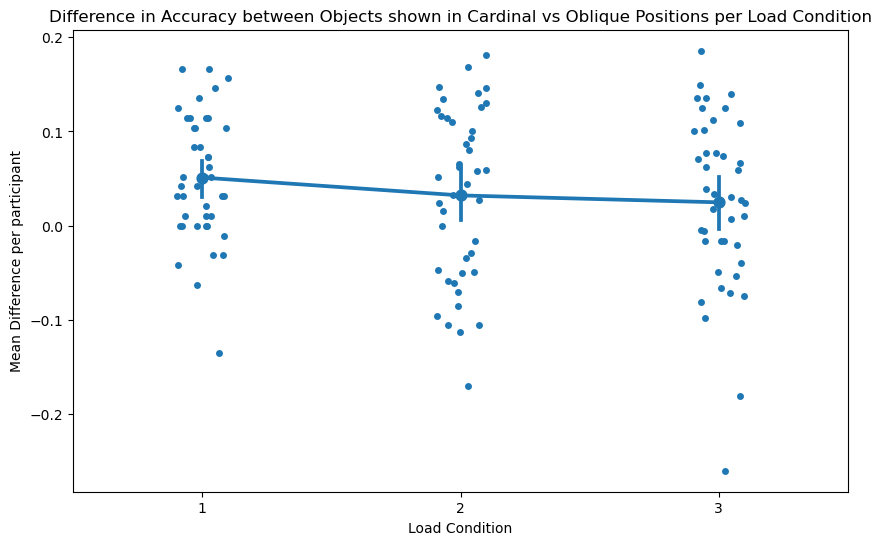

,Source,ddof1,ddof2,F,p-unc,p-GG-corr,ng2,eps,sphericity,W-spher,p-spher
0,items_presented,2,82,1.6561,0.1972,0.2018,0.0175,0.8403,False,0.81,0.0148


The t-test does not indicate a significant difference in the oblique effect depending on the laod condition.


In [12]:
# Subtracting differences in accuracy depending on cardinal vs oblique position
# Cardinal - Oblique Accuracy for every Load condition

obli_data_con1 = df.loc[df['items_presented']==1].groupby(['subID', 'items_presented', 'Cardinal_Category'])[('acc_trial_concrete_cued')].mean().reset_index()
obli_data_con2 = df.loc[df['items_presented']==2].groupby(['subID', 'items_presented', 'Cardinal_Category'])[('acc_trial_concrete_cued')].mean().reset_index()
obli_data_con3 = df.loc[df['items_presented']==3].groupby(['subID', 'items_presented', 'Cardinal_Category'])[('acc_trial_concrete_cued')].mean().reset_index()

obli_data_con1_piv = obli_data_con1.pivot(index=['subID', 'items_presented'], columns='Cardinal_Category', values='acc_trial_concrete_cued')
obli_data_con2_piv = obli_data_con2.pivot(index=['subID', 'items_presented'], columns='Cardinal_Category', values='acc_trial_concrete_cued')
obli_data_con3_piv = obli_data_con3.pivot(index=['subID', 'items_presented'], columns='Cardinal_Category', values='acc_trial_concrete_cued')


obli_data_con1_piv['Difference'] = obli_data_con1_piv['Cardinal'].sub(obli_data_con1_piv['Oblique'])
obli_data_con2_piv['Difference'] = obli_data_con2_piv['Cardinal'].sub(obli_data_con2_piv['Oblique'])
obli_data_con3_piv['Difference'] = obli_data_con3_piv['Cardinal'].sub(obli_data_con3_piv['Oblique'])

all_tables_subs = pd.concat([obli_data_con1_piv, obli_data_con2_piv, obli_data_con3_piv]).reset_index()
display(all_tables_subs)

plt.figure(figsize=(10,6))
sns.stripplot(data=all_tables_subs, x='items_presented', y='Difference', jitter=0.1) #(x='Cardinal_Category', y='acc_trial_concrete_cued', data=final_grouped_data_obli)
sns.pointplot(data=all_tables_subs, x='items_presented', y='Difference')
plt.title('Difference in Accuracy between Objects shown in Cardinal vs Oblique Positions per Load Condition')
plt.xlabel('Load Condition')
plt.ylabel('Mean Difference per participant')
plt.show()

alpha = 0.05

result_anova_repeated = pg.rm_anova(data=all_tables_subs, dv='Difference', within=['items_presented'], subject='subID')


# result_anova_single = pg.anova(data=all_tables_subs, dv='Difference', between='items_presented')
display(result_anova_repeated.round(4))
p_value = result_anova_repeated['p-unc'].values

if p_value < alpha:
    print("The ANOVA indicates a significant difference in the oblique effect depending on the laod condition.")
else:
    print("The t-test does not indicate a significant difference in the oblique effect depending on the laod condition.")

### Oblique effect on polar plot

acc_df: object_cued_rot  items_presented
11.25            1                  0.851190
                 2                  0.718690
                 3                  0.705773
33.75            1                  0.791667
                 2                  0.731225
                 3                  0.701923
56.25            1                  0.785714
                 2                  0.642447
                 3                  0.593878
78.75            1                  0.797619
                 2                  0.731610
                 3                  0.637295
101.25           1                  0.815476
                 2                  0.713978
                 3                  0.629482
123.75           1                  0.734127
                 2                  0.666008
                 3                  0.629259
146.25           1                  0.763889
                 2                  0.701375
                 3                  0.633270
168.75        

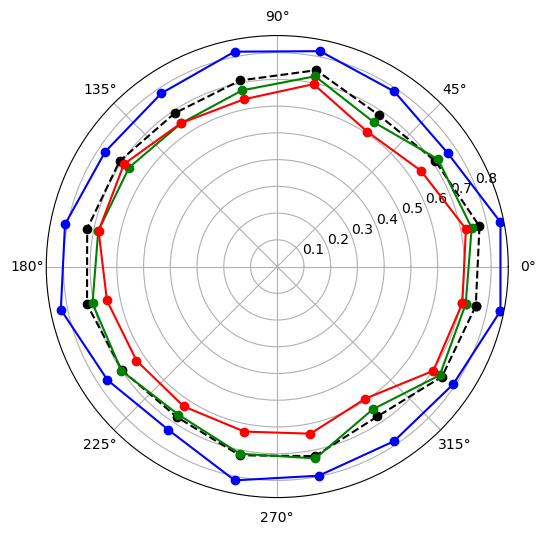

In [13]:
## Plotting the Oblique effect on a polar plot

spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)

## change the above line to make it so that positive is going anticlockwise. Apparently theta is always going anticlockwise

# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])

acc_per_ori = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean().values

acc_df = df.groupby(by=['object_cued_rot', 'items_presented'])['acc_trial_concrete_cued'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
oriacc1 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 1].to_numpy()
oriacc2 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 2].to_numpy()
oriacc3 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 3].to_numpy()

print("acc_df:", acc_df)
print("oriacc1:", oriacc1)
print("oriacc2:", oriacc2)
print("oriacc3:", oriacc3)

# Create the polar plot
fig = plt.figure(figsize=(10,6))
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
# mbp_rad = np.append(mbp_rad, mbp_rad[0])
# mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
# mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
# mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

acc_per_ori_circ = np.append(acc_per_ori, acc_per_ori[0])
oriacc1_circ = np.append(oriacc1, oriacc1[0])
oriacc2_circ = np.append(oriacc2, oriacc2[0])
oriacc3_circ = np.append(oriacc3, oriacc3[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, acc_per_ori_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
# ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, oriacc1_circ, 'bo-')
ax.plot(-spacing_circ, oriacc2_circ, 'go-')
ax.plot(-spacing_circ, oriacc3_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


## Cardinal Repulsion

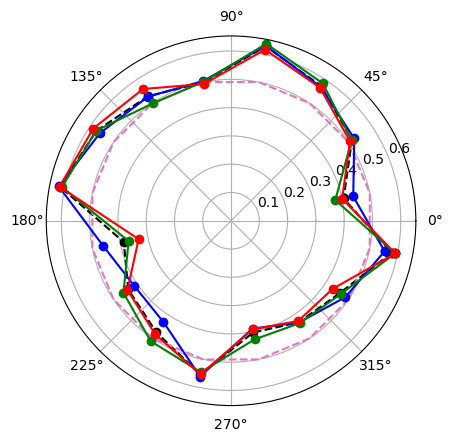

In [14]:
# Cardinal Repulsion Polar Plot

# Note: Check the following notes to make sure I did everything corret
# Note: check that theta and direction are correct - check with Juan and check Juan's code

# spacing is what is usually called theta in the polar plots. not sure if this is correct or just a butched way that works, 
# could also be coded using np.arange of divisions of pi, which is more common practice but harder to read
theta = np.arange(11.25, 360, 22.5)
theta_rad = np.radians(theta)

# making it a full circle
theta_circ = np.append(theta_rad, theta_rad[0])

# seperate by con
mbp_per_ori = df.groupby('object_cued_rot')['button_press_clockwise'].mean().reset_index()
mbp_df = df.groupby(by=['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean().reset_index()

mbp1 = mbp_df.loc[mbp_df['items_presented'] == 1, 'button_press_clockwise'].reset_index()
mbp2 = mbp_df.loc[mbp_df['items_presented'] == 2, 'button_press_clockwise'].reset_index()
mbp3 = mbp_df.loc[mbp_df['items_presented'] == 3, 'button_press_clockwise'].reset_index()


# display("MBP:", mbp_per_ori)
# display("MBP1:", mbp1)
# display("MBP2:", mbp2)
# display("MBP3:", mbp3)

# Create the polar plot
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})

mbp_circ = pd.concat([mbp_per_ori, mbp_per_ori.loc[[0]]])

mbp1_circ = pd.concat([mbp1, mbp1.loc[[0]]])
mbp2_circ = pd.concat([mbp2, mbp2.loc[[0]]])
mbp3_circ = pd.concat([mbp3, mbp3.loc[[0]]])

# Plot the data for the general mbp
ax.plot(-theta_circ, mbp_circ['button_press_clockwise'], 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
ax.plot(-theta_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-theta_circ, mbp1_circ['button_press_clockwise'], 'bo-')
ax.plot(-theta_circ, mbp2_circ['button_press_clockwise'], 'go-')
ax.plot(-theta_circ, mbp3_circ['button_press_clockwise'], 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


### T-test against zero for all conditions together and every condition individually

In [15]:
# Grouping the data by the necessary keys and producing a mean for button press clockwise for every condition and orientation and subject ID

df_grouped = df.groupby(['subID', 'items_presented','object_cued_rot']).agg({'button_press_clockwise':(['mean'])}, as_index=False)
display(df_grouped)

# Grouping by Condition
condition_grps = df_grouped.groupby('items_presented', as_index=False)
# Condition 1
condition_1 = condition_grps.get_group(1).reset_index()
# Condition 2
condition_2 = condition_grps.get_group(2).reset_index()
# Condition 3
condition_3 = condition_grps.get_group(3).reset_index()


button_press_clockwise
                                                         mean
subID  items_presented object_cued_rot                       
1L974Q 1               11.25                         0.500000
                       33.75                         0.166667
                       56.25                         0.500000
                       78.75                         0.250000
                       101.25                        0.416667
...                                                       ...
ZGV9KP 3               258.75                        0.461538
                       281.25                        0.666667
                       303.75                        0.411765
                       326.25                        0.500000
                       348.75                        0.272727

[2016 rows x 1 columns]

In [16]:


# all conditions

all_differences_all_con = []
subIDs = []
for i in good_partis: 
    df_grouped_all_con = df.groupby(['subID', 'object_cued_rot']).agg({'button_press_clockwise':(['mean'])}, as_index=False).reset_index()
    participant_grps = df_grouped_all_con.groupby('subID', as_index=False)
    participant_data = participant_grps.get_group(i)
    differences = []
    
    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

        # Calculate the difference and append to the list
        difference =  value_x - value_y
        differences.append(difference)

    mean_difference = np.mean(differences)
    all_differences_all_con.append(mean_difference)
    #trying to append the subID here within the loop to the difference value, need to go into a new column
    
    subIDs.append(i)


#suggestion from chatGPT, commented out the stuff below 
differences_df_all_con = pd.DataFrame({'subID': subIDs, 'Mean_Difference': all_differences_all_con})
display(differences_df_all_con)

ttest_results = pg.ttest(differences_df_all_con['Mean_Difference'], 0)
display(ttest_results.round(4))

p_value = ttest_results['p-val'].values

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in cardinal bias from 0 across all load conditions.")
else:
    print("The t-test does not indicate a significant difference in cardinal bias from 0 across all load conditions.")

,subID,Mean_Difference
0,Z16JQR,0.127873
1,C9A31N,-0.015541
2,LPULPG,0.123089
3,R8CW7K,0.231509
4,D62XJG,0.321022
5,XXRRPP,0.215403
6,ZGV9KP,0.376675
7,JMUA97,0.062046
8,Z632AK,0.135116
9,AGYVK9,0.081452


,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,8.8514,41,two-sided,0.0,"[0.13, 0.21]",1.3658,2.112e+08,1.0


The t-test indicates a significant difference in cardinal bias from 0 across all load conditions.


In [17]:
all_differences_con1 = []
subIDs = []
for i in good_partis: 
    participant_grp = condition_1.groupby('subID', as_index=False)
    participant_data = participant_grp.get_group(i)
    differences = []

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()
    
        # Calculate the difference and append to the list
        difference =  value_x - value_y
        differences.append(difference)

    mean_difference = np.mean(differences)
    all_differences_con1.append(mean_difference)
    #trying to append the subID here within the loop to the difference value, need to go into a new column
    
    subIDs.append(i)


#suggestion from chatGPT, commented out the stuff below 
differences_df_con1 = pd.DataFrame({'subID': subIDs, 'Mean_Difference': all_differences_con1})
display(differences_df_con1)

ttest_results = pg.ttest(differences_df_con1['Mean_Difference'], 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))

p_value = ttest_results['p-val'].values

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in cardinal bias from 0 in load condition 1.")
else:
    print("The t-test does not indicate a significant difference in cardinal bias from 0 in load condition 1.")

,subID,Mean_Difference
0,Z16JQR,0.000000
1,C9A31N,-0.145833
2,LPULPG,0.104167
3,R8CW7K,0.229167
4,D62XJG,0.187500
5,XXRRPP,0.333333
6,ZGV9KP,0.250000
7,JMUA97,0.125000
8,Z632AK,0.208333
9,AGYVK9,-0.020833


,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,5.9638,41,two-sided,0.0,"[0.09, 0.19]",0.9202,3.307e+04,0.9999


The t-test indicates a significant difference in cardinal bias from 0 in load condition 1.


In [18]:
all_differences_con2 = []
subIDs = []
for i in good_partis: 
    participant_grp = condition_2.groupby('subID', as_index=False)
    participant_data = participant_grp.get_group(i)
    differences = []

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

        # Calculate the difference and append to the list
        difference =  value_x - value_y
        differences.append(difference)

    mean_difference = np.mean(differences)
    all_differences_con2.append(mean_difference)
    #trying to append the subID here within the loop to the difference value, need to go into a new column
    
    subIDs.append(i)


#suggestion from chatGPT, commented out the stuff below 
differences_df_con2 = pd.DataFrame({'subID': subIDs, 'Mean_Difference': all_differences_con2})
display(differences_df_con2)

ttest_results = pg.ttest(differences_df_con2['Mean_Difference'], 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))

p_value = ttest_results['p-val'].values

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in cardinal bias from 0 in load condition 2.")
else:
    print("The t-test does not indicate a significant difference in cardinal bias from 0 in load condition 2.")

,subID,Mean_Difference
0,Z16JQR,0.126042
1,C9A31N,-0.028480
2,LPULPG,0.195979
3,R8CW7K,0.345583
4,D62XJG,0.417096
5,XXRRPP,0.257008
6,ZGV9KP,0.505352
7,JMUA97,-0.062874
8,Z632AK,0.021284
9,AGYVK9,0.123397


,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,6.8523,41,two-sided,0.0,"[0.13, 0.24]",1.0573,5.075e+05,1.0


The t-test indicates a significant difference in cardinal bias from 0 in load condition 2.


In [19]:
all_differences_con3 = []
subIDs = []
for i in good_partis: 
    participant_grp = condition_3.groupby('subID', as_index=False)
    participant_data = participant_grp.get_group(i)
    differences = []

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

        # Calculate the difference and append to the list
        difference =  value_x - value_y
        differences.append(difference)

    mean_difference = np.mean(differences)
    all_differences_con3.append(mean_difference)
    #trying to append the subID here within the loop to the difference value, need to go into a new column
    
    subIDs.append(i)


#suggestion from chatGPT, commented out the stuff below 
differences_df_con3 = pd.DataFrame({'subID': subIDs, 'Mean_Difference': all_differences_con3})
display(differences_df_con3)

ttest_results = pg.ttest(differences_df_con3['Mean_Difference'], 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))

p_value = ttest_results['p-val'].values

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in cardinal bias from 0 in load condition 3.")
else:
    print("The t-test does not indicate a significant difference in cardinal bias from 0 in load condition 3.")


,subID,Mean_Difference
0,Z16JQR,0.231215
1,C9A31N,0.151944
2,LPULPG,0.076168
3,R8CW7K,0.127930
4,D62XJG,0.308532
5,XXRRPP,0.052471
6,ZGV9KP,0.381352
7,JMUA97,0.118288
8,Z632AK,0.194705
9,AGYVK9,0.172611


,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,7.6911,41,two-sided,0.0,"[0.14, 0.23]",1.1868,6.588e+06,1.0


The t-test indicates a significant difference in cardinal bias from 0 in load condition 3.


### ANOVA comparing the cardinal repulsion in the load conditions

,subID,Mean_Difference,items_presented
0,Z16JQR,0.000000,1
1,C9A31N,-0.145833,1
2,LPULPG,0.104167,1
3,R8CW7K,0.229167,1
4,D62XJG,0.187500,1
...,...,...,...
37,8H3YTN,-0.007097,3
38,TNNWZN,0.464726,3
39,R62CC9,0.203251,3
40,XG7QAG,0.317415,3


,Source,ddof1,ddof2,F,p-unc,np2
0,items_presented,2,123,0.88333,0.41601,0.01416


The ANOVA test indicates a significant difference among the load conditions.


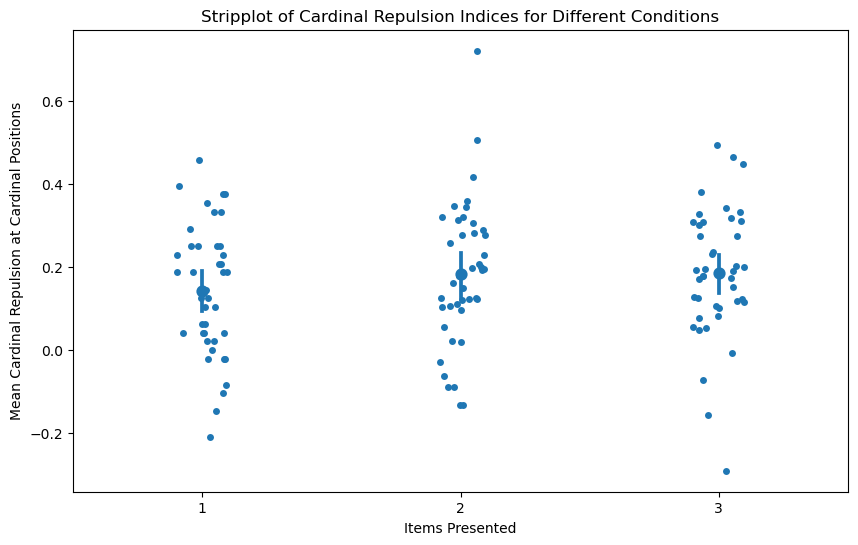

In [20]:
# Pingouin ANOVA + plot 

differences_df_con1['items_presented'] = 1
differences_df_con2['items_presented'] = 2
differences_df_con3['items_presented'] = 3

combined_df2 = pd.concat([differences_df_con1, differences_df_con2, differences_df_con3])
display(combined_df2)

anova_results = pg.anova(data=combined_df2, dv='Mean_Difference', between='items_presented')

# Display ANOVA results
display(anova_results)

# Define the significance level (alpha)
alpha = 0.05

if p_value < alpha:
    print("The ANOVA test indicates a significant difference among the load conditions.")
else:
    print("The ANOVA test does not indicate a significant difference among the load conditions.")

plt.figure(figsize=(10, 6))  # Set the figure size

# Create a boxplot
sns.stripplot(data=combined_df2, x='items_presented', y='Mean_Difference')
sns.pointplot(data=combined_df2, x='items_presented', y='Mean_Difference', estimator='mean', linestyles='none')
plt.xlabel('Items Presented')
plt.ylabel('Mean Cardinal Repulsion at Cardinal Positions')
plt.title('Stripplot of Cardinal Repulsion Indices for Different Conditions')
plt.show()

# The following snippets need to be looked through and potentially deleted

In [21]:
# Continue here: check wether this could be useful - maybe easier than above


# what did I do this for, this seems pretty perfect actually
# ah yes, with the multiple keys within the groupby, I need to specifically use get_group with all three exact 
# the reset_index at the end makes it a pandas dataframe again??? so weird. sometimes reset_index makes it a series and here
# a dataframe again?

mbp_df_2 = df.groupby(by=['object_cued_rot', 'items_presented', 'subID'])['button_press_clockwise'].mean().reset_index()
mbp_df_con = mbp_df_2.groupby('items_presented')
display('1:', mbp_df_2)
display('2:', mbp_df_con)
type(mbp_df_2)

# for key, item in mbp_df_2:
#     print(mbp_df_2.get_group(key), "\n\n")

# mbp_df_2.groups
# using mean() at the end of the groupby disables the groupby function


con_1 = mbp_df_con.get_group((1))
display('3:',con_1)

# # loc[(mbp_df_2['object_cued_rot'] == '11.25'), ['button_press_clockwise']]
con_2 = mbp_df_con.get_group((2))
con_3 = mbp_df_con.get_group((3))

'1:'

,object_cued_rot,items_presented,subID,button_press_clockwise
0,11.25,1,1L974Q,0.500000
1,11.25,1,1UVQEK,0.583333
2,11.25,1,30K8XE,0.500000
3,11.25,1,35T018,0.750000
4,11.25,1,45G1TX,0.250000
...,...,...,...,...
2011,348.75,3,XG7QAG,0.200000
2012,348.75,3,XXRRPP,0.545455
2013,348.75,3,Z16JQR,0.230769
2014,348.75,3,Z632AK,0.200000


'2:'

'3:'

,object_cued_rot,items_presented,subID,button_press_clockwise
0,11.25,1,1L974Q,0.500000
1,11.25,1,1UVQEK,0.583333
2,11.25,1,30K8XE,0.500000
3,11.25,1,35T018,0.750000
4,11.25,1,45G1TX,0.250000
...,...,...,...,...
1927,348.75,1,XG7QAG,0.166667
1928,348.75,1,XXRRPP,0.583333
1929,348.75,1,Z16JQR,0.583333
1930,348.75,1,Z632AK,0.500000


In [22]:
oris = []
oris_value = 11.25

while oris_value <= 360:
    oris.append(oris_value)
    oris_value = oris_value + 360/16

print(oris)

# oris_unique = df['object_cued_rot'].unique()
# oris_unique = np.sort(oris_unique)
oris_unique = np.sort(df['object_cued_rot'].unique())
oris_unique


[11.25, 33.75, 56.25, 78.75, 101.25, 123.75, 146.25, 168.75, 191.25, 213.75, 236.25, 258.75, 281.25, 303.75, 326.25, 348.75]


array([ 11.25,  33.75,  56.25,  78.75, 101.25, 123.75, 146.25, 168.75,
       191.25, 213.75, 236.25, 258.75, 281.25, 303.75, 326.25, 348.75])

In [23]:
# # Trying to do the Cardinal Bias in one block
# conditions = df['items_presented'].unique()

# for condition in conditions:
#     condition_2 = condition_grps.get_group(2).reset_index()

In [24]:
#using seaborn and pingouin


# I want to calculate the difference between the two orientations closest to the cardinal axes and take the average of those
# four numbers 
# either the hypothesis is that the difference between the two points is lower than zero or higher than zero (?)

# x0 - y0

# x90 - y90

# x180 - y180

# x270 - y270

# mean der 4 zahlen

# - -> 1 index pro proband

# erwartung: höher als 0

# testing mit 1-sample-t-test against 0
result_dict = {}
result_list_index = []

for i in good_partis:
    
    participant_data = df[df['subID']==i]

    # Create an empty list to store values for each participant
    participant_values_x = []
    participant_values_y = []

    for ori in [11.25, 101.25, 191.25, 281.25]:
        participant_data_ori_x = participant_data.loc[participant_data['object_cued_rot'] == ori, ['object_cued_rot', 'button_press_clockwise']].mean()
      
        # Append the 'button_press_clockwise' values to the list
        participant_values_x.append(participant_data_ori_x)
    
    for ori in [348.75, 78.75, 168.75, 258.75]:
        participant_data_ori_y = participant_data.loc[participant_data['object_cued_rot'] == ori, ['object_cued_rot', 'button_press_clockwise']].mean()
      
        # Append the 'button_press_clockwise' values to the list
        participant_values_y.append(participant_data_ori_y)
    
        #index = (participant_values_x - participant_values_y)
        #result_list_index.append(index)
    # participant_index = participant_values_x - participant_values_y

    # Store the lists of values in the dictionary with participant ID as the key
    result_dict[i] = {'participant_data_ori_x': participant_values_x, 'participant_data_ori_y': participant_values_y, } # 'participant_index': participant_index

display(participant_data_ori_y)
# display(type(result_dict))
# result_dict_df = pd.concat(result_dict)
# display(result_dict_df)
        
# Print or use the result_dict as needed
# for participant_id, values_dict in result_dict.items():
#     print(f"Participant {participant_id}:")
#     print("participant_data_ori_x:", values_dict['participant_data_ori_x'])
#     print("participant_data_ori_y:", values_dict['participant_data_ori_y'])

display(result_list_index)

object_cued_rot           258.750000
button_press_clockwise      0.973684
dtype: float64

[]

In [25]:
display(type(participant_values_y))
display(type(participant_data_ori_y))

list

pandas.core.series.Series

In [26]:
# Is this all conditions?

mean_differences = []

for i in good_partis: 
    participant_data = df[df['subID'] == i]

    differences = []

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

        # Calculate the difference and append to the list
        difference =  value_x - value_y
        
        differences.append(difference)

    mean_difference = np.mean(differences)
    print(i, mean_difference)

    mean_differences.append(mean_difference)


# the ttest works on differences, but not on mean differences. Why?
# since it seems to be an issue that there is no variance, maybe I need the full data per participant  
ttest_results = pg.ttest(mean_differences, 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))


z_part_result = (0.000000 + 0.126042 + 0.231215)/3
display(z_part_result)
# 

Z16JQR 0.12787291270633935
C9A31N -0.015541419531232795
LPULPG 0.12308945389440745
R8CW7K 0.23150862617774381
D62XJG 0.32102179559734745
XXRRPP 0.21540266393207572
ZGV9KP 0.37667491737794473
JMUA97 0.06204622737130479
Z632AK 0.1351155637741004
AGYVK9 0.08145202574865883
KJN4WD 0.12023914225454661
NPLPMR 0.23912832246076615
TEPWRW 0.15563961388698824
Q0MMZQ 0.07668791666953431
T4LJ1R 0.08878242353852107
UZYJ8Q 0.3205738929951722
GJL7U8 0.11494226156789827
5T547Z 0.21331628188673338
RP15M5 0.09418966450216451
TPLGJP 0.2294830811247422
REUNMA 0.08010365256851076
VY0RJ8 0.18732791490890768
6TQVJE 0.1385349362481598
7NEW5C 0.24453848525055955
Q8245X 0.2725138999674177
5KRM35 0.12516141754184262
H9PP50 0.1706996008621374
AZ2X8A 0.24058121541021676
1UVQEK 0.21007159644655055
CD2D5R 0.16126865586011713
35T018 0.21070614346225816
KM26F9 0.5431122531234763
UCXTVD 0.03312870210055033
1L974Q 0.21224239314222332
CYPUTL 0.31974787158610685
4A2K27 0.14979095105258455
45G1TX -0.21601040535831556
8H3YT

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,8.8514,41,two-sided,0.0,"[0.13, 0.21]",1.3658,2.112e+08,1.0


0.11908566666666666

In [27]:
test = df['items_presented'].unique()
display(test)

array([1, 3, 2])

In [28]:
# Code by Dilara

mean_differences = np.empty([len(good_partis),len(df['items_presented'].unique())])

for j,load in enumerate(df['items_presented'].unique()):

    for i in good_partis: 
        data = df[(df['subID'] == i) & (df['items_presented'] == load)]
        differences = []

        # Define the pairs of orientations for subtraction
        orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

        for ori_x, ori_y in orientation_pairs:
            value_x = data.loc[data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
            value_y = data.loc[data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

            # Calculate the difference and append to the list
            difference =  value_x - value_y
            
            differences.append(difference)
    display(mean_differences)
    mean_differences[i,j] = np.mean(differences)
    # mean_differences[i,j]

# the ttest works on differences, but not on mean differences. Why?
# since it seems to be an issue that there is no variance, maybe I need the full data per participant  
rm_anova_results = pg.rm_anova(data=mean_differences)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
print(f"T-Test for each Participant:\n{ttest_results}")

array([[0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [0.e+000, 0.e+000, 0.e+000],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.e-324],
       [5.e-324, 5.e-324, 5.

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [ ]:
type(mean_differences)

In [ ]:
# can try and continue here?

for i in good_partis:
    filt_ori_pp = (df['subID'] == i) & (df['items_presented'] == 1)
    participant_data = df.loc[filt_ori_pp, ['subID', 'items_presented', 'object_cued_rot', 'acc_trial_concrete_cued']]
    # print(participant_data)
    groupby_by_object = participant_data.groupby(['object_cued_rot'])
    display(groupby_by_object.get_group(11.25))

In [ ]:
# values_y_array = np.array(participant_values_y[])
# values_x_array = np.array(participant_values_x)    
# print(values_y_array)
# print(values_x_array)
# result_index = values_y_array - values_x_array
# print(result_index)
df1 = pd.DataFrame({'A': [1, 2, 3]})
df2 = pd.DataFrame({'B': [4, 5, 6]})
participant_values_x = [df1, df2]
print('x_values', participant_values_x)

df3 = pd.DataFrame({'A': [7, 8, 9]})
df4 = pd.DataFrame({'B': [10, 11, 12]})
participant_values_y = [df3, df4]
print('y_values', participant_values_y)

# Using zip to pair DataFrames from participant_values_x and participant_values_y
paired_dataframes = zip(participant_values_x, participant_values_y)


# Printing the paired_dataframes
for x, y in paired_dataframes:
    print("DataFrame X:")
    print(x)
    print("DataFrame Y:")
    print(y)
    print("-----------")

In [ ]:
# What is the difference between:
data1 = df[df['subID'] == i].groupby(['stimuli_set'])['acc_trial_concrete_cued'].mean()
print(data1)
# and
data2 = df.loc[df['subID'] == i, ['stimuli_set', 'acc_trial_concrete_cued']].mean()
print(data2)

In [ ]:
freqs = []

for i in good_partis:


    freqs2 = [i, 200]
    freqs.append(freqs2)
    freqs

display(freqs)